In [4]:
import os
import glob
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
import torchvision.transforms.functional as TF
import kagglehub
from PIL import Image
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


In [5]:
class Random90Rotation:
    def __call__(self, img):
        angle = random.choice([0, 90, 180, 270])
        return TF.rotate(img, angle)

class CustomWeedDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []

        all_files = []
        for ext in ["*.jpg", "*.jpeg", "*.png"]:
            all_files.extend(glob.glob(os.path.join(root_dir, "**", ext), recursive=True))

        class_names = set()
        for f in all_files:
            filename = os.path.basename(f)
            if "_" in filename:
                class_names.add(filename.split("_")[0])

        self.classes = sorted(list(class_names))
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}

        for f in all_files:
            filename = os.path.basename(f)
            if "_" in filename:
                class_name = filename.split("_")[0]
                self.image_paths.append(f)
                self.labels.append(self.class_to_idx[class_name])

    def __len__(self): return len(self.image_paths)
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        label = self.labels[idx]
        if self.transform: image = self.transform(image)
        return image, label

path = kagglehub.dataset_download("jaidalmotra/weed-detection")
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    Random90Rotation(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

full_dataset = CustomWeedDataset(root_dir=path, transform=data_transforms)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

class_names = full_dataset.classes
print(f"Sınıflar: {class_names} | Toplam: {len(full_dataset)}")


Using Colab cache for faster access to the 'weed-detection' dataset.
Sınıflar: ['Rumex-obtusifolius-L', 'ridderzuring'] | Toplam: 1906


In [6]:
class ReverseAttention(nn.Module):
    def __init__(self, in_channels):
        super(ReverseAttention, self).__init__()
        self.conv_in = nn.Conv2d(in_channels, 1, kernel_size=1)
        self.conv_out = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x, high_level_mask=None):
        if high_level_mask is not None:
            high_level_mask = nn.functional.interpolate(high_level_mask, size=x.size()[2:], mode='bilinear', align_corners=True)
            x = x * (1.0 - high_level_mask)
        return self.conv_out(x), self.sigmoid(self.conv_in(x))

class ResNet50ReverseAttention(nn.Module):
    def __init__(self, num_classes):
        super(ResNet50ReverseAttention, self).__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.backbone1 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool, resnet.layer1)
        self.backbone2 = resnet.layer2
        self.backbone3 = resnet.layer3
        self.backbone4 = resnet.layer4

        self.u4 = nn.Conv2d(2048, 1, kernel_size=1)
        self.ra3 = ReverseAttention(1024)
        self.ra2 = ReverseAttention(512)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(3584, num_classes)

    def forward(self, x):
        f1 = self.backbone1(x)
        f2 = self.backbone2(f1)
        f3 = self.backbone3(f2)
        f4 = self.backbone4(f3)

        mask4 = torch.sigmoid(self.u4(f4))
        out3, mask3 = self.ra3(f3, mask4)
        out2, mask2 = self.ra2(f2, mask3)

        out = torch.cat([self.avgpool(out2), self.avgpool(out3), self.avgpool(f4)], dim=1)
        return self.fc(torch.flatten(out, 1))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ResNet50ReverseAttention(num_classes=len(class_names)).to(device)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 200MB/s]


In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

for epoch in range(100):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    print(f"Epoch {epoch+1}/100 - Loss: {running_loss / len(train_loader.dataset):.4f}")


Epoch 1/100 - Loss: 0.6676
Epoch 2/100 - Loss: 0.5303
Epoch 3/100 - Loss: 0.4122
Epoch 4/100 - Loss: 0.3583
Epoch 5/100 - Loss: 0.2730
Epoch 6/100 - Loss: 0.2295
Epoch 7/100 - Loss: 0.2147
Epoch 8/100 - Loss: 0.1518
Epoch 9/100 - Loss: 0.1807
Epoch 10/100 - Loss: 0.1463
Epoch 11/100 - Loss: 0.1183
Epoch 12/100 - Loss: 0.1064
Epoch 13/100 - Loss: 0.0748
Epoch 14/100 - Loss: 0.0642
Epoch 15/100 - Loss: 0.0604
Epoch 16/100 - Loss: 0.0648
Epoch 17/100 - Loss: 0.0307
Epoch 18/100 - Loss: 0.0334
Epoch 19/100 - Loss: 0.0512
Epoch 20/100 - Loss: 0.0442
Epoch 21/100 - Loss: 0.0301
Epoch 22/100 - Loss: 0.0253
Epoch 23/100 - Loss: 0.0448
Epoch 24/100 - Loss: 0.0473
Epoch 25/100 - Loss: 0.0601
Epoch 26/100 - Loss: 0.0650
Epoch 27/100 - Loss: 0.0543
Epoch 28/100 - Loss: 0.0417
Epoch 29/100 - Loss: 0.0548
Epoch 30/100 - Loss: 0.0361
Epoch 31/100 - Loss: 0.0321
Epoch 32/100 - Loss: 0.0671
Epoch 33/100 - Loss: 0.0457
Epoch 34/100 - Loss: 0.0405
Epoch 35/100 - Loss: 0.0279
Epoch 36/100 - Loss: 0.0163
E

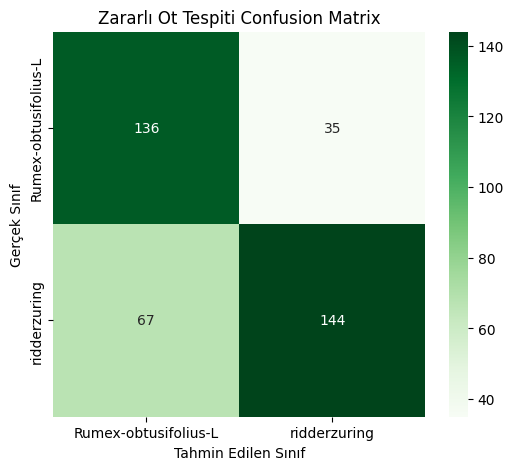

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        _, preds = torch.max(model(images), 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names)
plt.ylabel('Gerçek Sınıf')
plt.xlabel('Tahmin Edilen Sınıf')
plt.title('Zararlı Ot Tespiti Confusion Matrix')
plt.savefig('confusion_matrix.png')
plt.show()

torch.save(model.state_dict(), 'resnet50_reverse_attention_weed.pth')
from google.colab import files
files.download('resnet50_reverse_attention_weed.pth')
files.download('confusion_matrix.png')


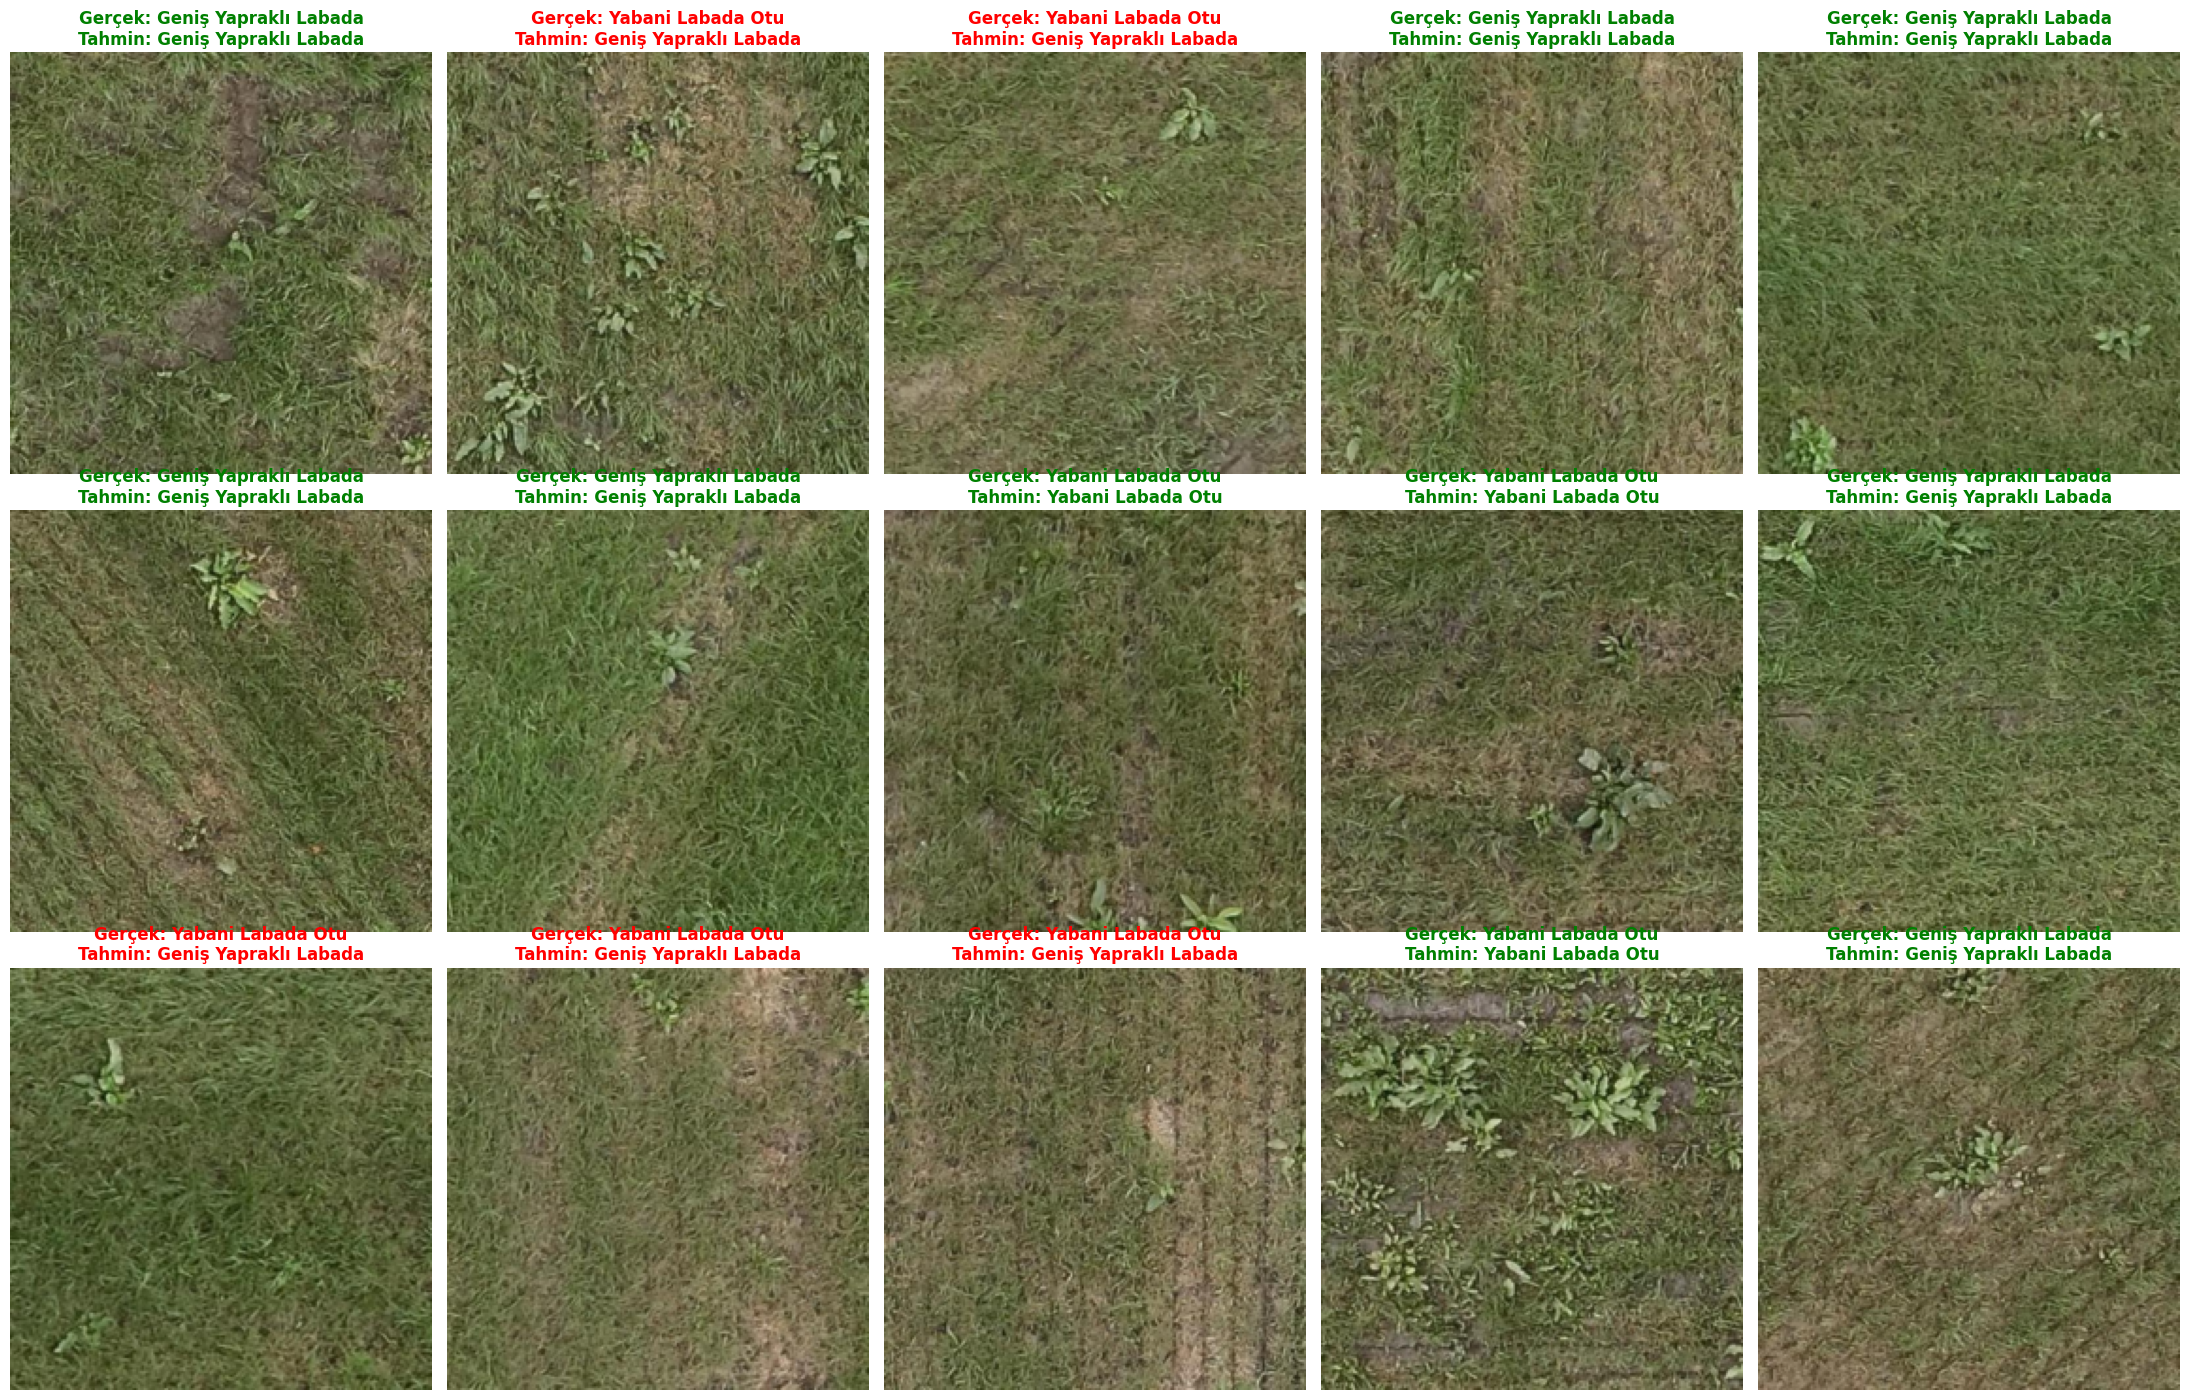

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
model.eval()
sample_images = []
sample_preds = []
sample_labels = []

turkce_ceviriler = {
    'Rumex-obtusifolius-L': 'Geniş Yapraklı Labada',
    'ridderzuring': 'Yabani Labada Otu'
}

with torch.no_grad():
    for images, labels in val_loader:
        images_dev = images.to(device)
        outputs = model(images_dev)
        _, preds = torch.max(outputs, 1)

        for i in range(images.size(0)):
            if len(sample_images) < 15:
                img = images[i].permute(1, 2, 0).cpu().numpy()
                mean = np.array([0.485, 0.456, 0.406])
                std = np.array([0.229, 0.224, 0.225])
                img = std * img + mean
                img = np.clip(img, 0, 1)

                sample_images.append(img)
                sample_preds.append(preds[i].item())
                sample_labels.append(labels[i].item())

        if len(sample_images) >= 15:
            break

fig, axes = plt.subplots(3, 5, figsize=(22, 14))
axes = axes.ravel()

for i in range(15):
    axes[i].imshow(sample_images[i])

    orijinal_gercek = class_names[sample_labels[i]]
    orijinal_tahmin = class_names[sample_preds[i]]

    gercek_ad = turkce_ceviriler.get(orijinal_gercek, orijinal_gercek)
    tahmin_ad = turkce_ceviriler.get(orijinal_tahmin, orijinal_tahmin)

    color = 'green' if sample_labels[i] == sample_preds[i] else 'red'

    axes[i].set_title(f"Gerçek: {gercek_ad}\nTahmin: {tahmin_ad}", color=color, fontsize=12, fontweight='bold')
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('model_15_test_ciktisi_turkce.png', bbox_inches='tight')
plt.show()

files.download('model_15_test_ciktisi_turkce.png')
